# Notebook 06 — Retreino dos modelos para validação externa

**Projeto de Iniciação Científica PIBIC — PUC-SP**
**Aluna:** Letícia Barboza de Godoi
**Orientador:** Prof. Dr. Renan Trevisoli Doria
**Curso:** Engenharia Biomédica

---

## Contexto

O Notebook 03 desenvolveu o pipeline original de estimativa de pressão arterial com 43 features (41 morfológicas + 2 de PTT), atingindo MAE de 3,63 mmHg (PAS) e 3,08 mmHg (PAD) após calibração linear por sujeito. O Notebook 05 reproduziu esses resultados com precisão de 0,004 mmHg, confirmando a robustez metodológica.

Para a validação externa no PulseDB (próximos notebooks), porém, é necessário considerar duas restrições importantes do novo dataset:

1. **Ausência de ECG sincronizado utilizável**: o PulseDB fornece ECG normalizado, mas a detecção de picos R no canal de ECG **não pode ser garantida** com a mesma qualidade do PTT-PPG. Em consequência, as features dependentes do Pulse Transit Time (`ptt_s`, `ptt_ms`) **não podem ser calculadas** de forma confiável no PulseDB.

2. **PPG normalizado em [0, 1]**: o PulseDB entrega o sinal PPG pré-normalizado, enquanto o PTT-PPG fornece amplitude bruta. Features cujo valor depende da amplitude absoluta do sinal (`amplitude`, `peak_value`, `valley_value`, `variance`, `std`, `hjorth_activity`) **produzirão valores sistematicamente diferentes** entre os dois datasets, o que prejudica a aplicação direta do modelo treinado.

## Objetivo

Treinar **três versões** do modelo Random Forest sobre o PTT-PPG, com conjuntos de features progressivamente mais restritos, validar a perda de desempenho em cada caso e selecionar a configuração mais adequada para a validação externa.

| Versão | Features usadas | Propósito |
|---|---|---|
| **A** | 43 (todas) | Sanity check de reprodutibilidade |
| **B** | 41 (sem PTT) | Avaliar o impacto da remoção do PTT |
| **C** | **35** (sem PTT e sem escala-dependentes) | **Modelo final para validação externa** |

Para cada versão, replica-se o protocolo do NB03: validação Leave-One-Subject-Out (22 sujeitos × Random Forest com 200 árvores) seguida de calibração linear por sujeito (Estratégia B).

## Critérios de aceitação

A Versão C será considerada **adequada para validação externa** se o MAE pós-calibração permanecer abaixo de 5 mmHg para ambas as pressões — limite operacional do padrão AAMI/ISO 81060-2.

---


## 1. Importações e configuração

In [1]:
import os
import socket
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

warnings.filterwarnings("ignore")
np.random.seed(42)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.dpi"] = 100

print("Computador:", socket.gethostname())
print("Inicio:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"))
print("Bibliotecas carregadas.")

Computador: NtebookLeticia
Inicio: 07/06/2026 13:00:03
Bibliotecas carregadas.


In [2]:
# Caminhos do projeto
BASE_IC      = Path(r"C:\IC_PPG")
PASTA_DADOS  = BASE_IC / "Datasets" / "PTT_PPG"
PASTA_MODELO = BASE_IC / "Modelos_Salvos" / "PTT_PPG"
PASTA_FIGS   = BASE_IC / "Figuras_Geradas"

# Garante existencia das pastas
PASTA_MODELO.mkdir(parents=True, exist_ok=True)
PASTA_FIGS.mkdir(parents=True, exist_ok=True)

# Arquivos esperados (gerados pelo NB05)
arquivo_csv          = PASTA_DADOS / "_features_v2_clean.csv"
arquivo_classificacao = PASTA_DADOS / "_features_classificacao.csv"

for nome, caminho in [("CSV de features", arquivo_csv),
                      ("Classificacao das features", arquivo_classificacao)]:
    if caminho.exists():
        print(f"  OK   {nome:<28} {caminho.name}")
    else:
        raise FileNotFoundError(f"Arquivo faltando: {caminho}")

print()
print("Tudo pronto.")

  OK   CSV de features              _features_v2_clean.csv
  OK   Classificacao das features   _features_classificacao.csv

Tudo pronto.


## 2. Carregamento e preparação dos dados

Replica-se a preparação do NB05: carregamento do CSV, definição de META_COLS/FEATURE_COLS, remoção de linhas com targets faltantes e imputação de NaN nas features.


In [3]:
# Carregamento
df = pd.read_csv(arquivo_csv)
print(f"CSV carregado: {df.shape[0]} ciclos x {df.shape[1]} colunas")

# Definicoes do NB03/NB05
META_COLS = [
    "record", "subject", "condition", "cycle_idx", "peak_sample", "time_s",
    "bp_sys_start", "bp_sys_end", "bp_dia_start", "bp_dia_end",
    "age", "gender", "height", "weight",
]
TARGET_COLS = ["bp_sys_mean", "bp_dia_mean"]
FEATURE_COLS_TODAS = [c for c in df.columns if c not in META_COLS + TARGET_COLS]

print(f"Total de features identificadas: {len(FEATURE_COLS_TODAS)}")
assert len(FEATURE_COLS_TODAS) == 43, "Numero de features diferente do esperado!"

CSV carregado: 42305 ciclos x 59 colunas
Total de features identificadas: 43


In [4]:
# Filtra ciclos com targets validos
df_model = df.dropna(subset=TARGET_COLS).copy().reset_index(drop=True)
print(f"Apos remover targets ausentes: {len(df_model)} ciclos")

# Imputacao: mediana por sujeito -> mediana global
for col in FEATURE_COLS_TODAS:
    if df_model[col].isna().any():
        df_model[col] = df_model.groupby("subject")[col].transform(
            lambda x: x.fillna(x.median())
        )
        if df_model[col].isna().any():
            df_model[col] = df_model[col].fillna(df_model[col].median())

assert df_model[FEATURE_COLS_TODAS].isna().sum().sum() == 0
print("Imputacao concluida (sem NaN remanescente).")

Apos remover targets ausentes: 42305 ciclos
Imputacao concluida (sem NaN remanescente).


## 3. Definição das três configurações de features

Utiliza-se o arquivo `_features_classificacao.csv` gerado no NB05 para definir, de forma reprodutível, quais features integram cada versão.


In [5]:
df_class = pd.read_csv(arquivo_classificacao)

# Features por categoria
fs_invariante     = df_class.query("categoria == 'invariante'")["feature"].tolist()
fs_escala_dep     = df_class.query("categoria == 'escala_dependente'")["feature"].tolist()
fs_ecg_dep        = df_class.query("categoria == 'ecg_dependente'")["feature"].tolist()

# Definicao das 3 versoes
CONFIGURACOES = {
    "A": {
        "nome": "Todas as 43 features (replica NB03)",
        "features": FEATURE_COLS_TODAS,
    },
    "B": {
        "nome": "41 features (sem PTT)",
        "features": [f for f in FEATURE_COLS_TODAS if f not in fs_ecg_dep],
    },
    "C": {
        "nome": "35 features (sem PTT e sem escala-dependentes)",
        "features": [f for f in FEATURE_COLS_TODAS
                     if f not in fs_ecg_dep and f not in fs_escala_dep],
    },
}

print("CONFIGURACOES DEFINIDAS")
print("=" * 70)
for vid, cfg in CONFIGURACOES.items():
    print(f"\nVersao {vid}: {cfg['nome']}")
    print(f"  Numero de features: {len(cfg['features'])}")

# Validacao das contagens
assert len(CONFIGURACOES["A"]["features"]) == 43
assert len(CONFIGURACOES["B"]["features"]) == 41
assert len(CONFIGURACOES["C"]["features"]) == 35
print()
print("Numeros confirmados: 43, 41, 35.")

CONFIGURACOES DEFINIDAS

Versao A: Todas as 43 features (replica NB03)
  Numero de features: 43

Versao B: 41 features (sem PTT)
  Numero de features: 41

Versao C: 35 features (sem PTT e sem escala-dependentes)
  Numero de features: 35

Numeros confirmados: 43, 41, 35.


In [6]:
# Lista das features REMOVIDAS em cada versao (para registro)
print("Features REMOVIDAS em cada versao:")
print("-" * 50)
print(f"\nVersao A: nenhuma (mantem todas as 43)")
print(f"\nVersao B (sem PTT): {fs_ecg_dep}")
print(f"\nVersao C (sem PTT e sem escala-dependentes):")
print(f"  PTT:             {fs_ecg_dep}")
print(f"  Escala-dependentes: {fs_escala_dep}")

Features REMOVIDAS em cada versao:
--------------------------------------------------

Versao A: nenhuma (mantem todas as 43)

Versao B (sem PTT): ['ptt_s', 'ptt_ms']

Versao C (sem PTT e sem escala-dependentes):
  PTT:             ['ptt_s', 'ptt_ms']
  Escala-dependentes: ['amplitude', 'peak_value', 'valley_value', 'variance', 'std', 'hjorth_activity']


## 4. Funções de treino e avaliação

Replicam-se exatamente as funções utilizadas no NB05 (que por sua vez replicam o NB03), garantindo coerência entre os notebooks.


In [7]:
# Mesmos hiperparametros do NB03
RF_PARAMS = dict(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
)


def loso_predict(X, y, groups, rf_params, verbose=False):
    """LOSO: treina nos outros 21 sujeitos, prediz no sujeito-alvo."""
    sujeitos = sorted(np.unique(groups))
    pred = np.zeros(len(y), dtype=np.float64)
    for i, subj in enumerate(sujeitos):
        mask_treino = groups != subj
        mask_teste  = groups == subj
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[mask_treino], y[mask_treino])
        pred[mask_teste] = rf.predict(X[mask_teste])
        if verbose:
            print(f"    Sujeito {subj:<5} ({i+1:>2}/{len(sujeitos)}) "
                  f"-> {mask_teste.sum()} ciclos")
    return pred


def aplicar_calibracao_linear(pred_generico, y, groups, condicoes,
                              min_ciclos_calib=10):
    """Calibracao linear por sujeito (Estrategia B do NB03)."""
    pred_cal = pred_generico.copy()
    for subj in sorted(np.unique(groups)):
        mask_subj  = groups == subj
        mask_calib = mask_subj & (condicoes == "sit")
        mask_teste = mask_subj & (condicoes != "sit")
        if mask_calib.sum() > min_ciclos_calib:
            reg = LinearRegression()
            reg.fit(pred_generico[mask_calib].reshape(-1, 1),
                    y[mask_calib])
            pred_cal[mask_teste] = reg.predict(
                pred_generico[mask_teste].reshape(-1, 1)
            )
            pred_cal[mask_calib] = np.nan
    return pred_cal


def metricas(y_real, y_pred):
    """Conjunto de metricas: MAE, RMSE, R2, ME, SD, % em faixas BHS."""
    erros = y_real - y_pred
    abs_erros = np.abs(erros)
    return {
        "MAE":    mean_absolute_error(y_real, y_pred),
        "RMSE":   np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2":     r2_score(y_real, y_pred),
        "ME":     np.mean(erros),
        "SD":     np.std(erros, ddof=1),
        "pct_5":  100 * np.mean(abs_erros <= 5),
        "pct_10": 100 * np.mean(abs_erros <= 10),
        "pct_15": 100 * np.mean(abs_erros <= 15),
    }


def classificar_bhs(pct_5, pct_10, pct_15):
    """BHS: A se 60/85/95; B se 50/75/90; C se 40/65/85; D caso contrario."""
    if pct_5 >= 60 and pct_10 >= 85 and pct_15 >= 95: return "A"
    if pct_5 >= 50 and pct_10 >= 75 and pct_15 >= 90: return "B"
    if pct_5 >= 40 and pct_10 >= 65 and pct_15 >= 85: return "C"
    return "D"


def classificar_aami(me, sd):
    """AAMI/ISO 81060-2: passa se |ME| <= 5 e SD <= 8."""
    return "PASSA" if (abs(me) <= 5 and sd <= 8) else "FALHA"


print("Funcoes de treino e avaliacao prontas.")

Funcoes de treino e avaliacao prontas.


## 5. Execução das três versões

Para cada versão (A, B, C), executa-se sequencialmente: LOSO para PAS, LOSO para PAD, calibração linear e cálculo das métricas. Esta seção é a mais demorada do notebook (8 a 12 minutos no total).


In [8]:
# Prepara arrays comuns
y_sys     = df_model["bp_sys_mean"].values.astype(np.float32)
y_dia     = df_model["bp_dia_mean"].values.astype(np.float32)
groups    = df_model["subject"].values
condicoes = df_model["condition"].values
mask_avaliacao = (condicoes != "sit")

# Estrutura para armazenar resultados
resultados = {}

print(f"Tempo estimado total: 8-12 minutos")
print(f"Inicio: {datetime.now().strftime('%H:%M:%S')}")
print()

Tempo estimado total: 8-12 minutos
Inicio: 13:00:03



In [9]:
# ====== VERSAO A: 43 features ======
inicio = datetime.now()
print(f"### VERSAO A — 43 features (replica NB03) ###")
print(f"Inicio: {inicio.strftime('%H:%M:%S')}")

cfg = CONFIGURACOES["A"]
X = df_model[cfg["features"]].values.astype(np.float32)

print(f"\n  LOSO PAS ({len(cfg['features'])} features)...")
pred_sys = loso_predict(X, y_sys, groups, RF_PARAMS)

print(f"\n  LOSO PAD ({len(cfg['features'])} features)...")
pred_dia = loso_predict(X, y_dia, groups, RF_PARAMS)

# Calibracao linear
pred_sys_cal = aplicar_calibracao_linear(pred_sys, y_sys, groups, condicoes)
pred_dia_cal = aplicar_calibracao_linear(pred_dia, y_dia, groups, condicoes)

# Metricas (genericas)
mask_valido_sys_gen = ~np.isnan(pred_sys)
mask_valido_dia_gen = ~np.isnan(pred_dia)
m_sys_gen = metricas(y_sys[mask_valido_sys_gen], pred_sys[mask_valido_sys_gen])
m_dia_gen = metricas(y_dia[mask_valido_dia_gen], pred_dia[mask_valido_dia_gen])

# Metricas (calibradas) - so walk+run, excluindo NaN
mask_valido_sys = mask_avaliacao & ~np.isnan(pred_sys_cal)
mask_valido_dia = mask_avaliacao & ~np.isnan(pred_dia_cal)
m_sys_cal = metricas(y_sys[mask_valido_sys], pred_sys_cal[mask_valido_sys])
m_dia_cal = metricas(y_dia[mask_valido_dia], pred_dia_cal[mask_valido_dia])

resultados["A"] = {
    "cfg": cfg,
    "pred_sys": pred_sys, "pred_dia": pred_dia,
    "pred_sys_cal": pred_sys_cal, "pred_dia_cal": pred_dia_cal,
    "m_sys_gen": m_sys_gen, "m_dia_gen": m_dia_gen,
    "m_sys_cal": m_sys_cal, "m_dia_cal": m_dia_cal,
}

duracao = (datetime.now() - inicio).total_seconds()
print(f"\n  Versao A concluida em {duracao:.1f} s ({duracao/60:.1f} min)")
print(f"  PAS calibrado: MAE={m_sys_cal['MAE']:.2f} mmHg")
print(f"  PAD calibrado: MAE={m_dia_cal['MAE']:.2f} mmHg")

### VERSAO A — 43 features (replica NB03) ###
Inicio: 13:00:03

  LOSO PAS (43 features)...

  LOSO PAD (43 features)...

  Versao A concluida em 264.7 s (4.4 min)
  PAS calibrado: MAE=3.63 mmHg
  PAD calibrado: MAE=3.08 mmHg


In [10]:
# ====== VERSAO B: 41 features (sem PTT) ======
inicio = datetime.now()
print(f"\n### VERSAO B — 41 features (sem PTT) ###")
print(f"Inicio: {inicio.strftime('%H:%M:%S')}")

cfg = CONFIGURACOES["B"]
X = df_model[cfg["features"]].values.astype(np.float32)

print(f"\n  LOSO PAS ({len(cfg['features'])} features)...")
pred_sys = loso_predict(X, y_sys, groups, RF_PARAMS)

print(f"\n  LOSO PAD ({len(cfg['features'])} features)...")
pred_dia = loso_predict(X, y_dia, groups, RF_PARAMS)

pred_sys_cal = aplicar_calibracao_linear(pred_sys, y_sys, groups, condicoes)
pred_dia_cal = aplicar_calibracao_linear(pred_dia, y_dia, groups, condicoes)

mask_valido_sys_gen = ~np.isnan(pred_sys)
mask_valido_dia_gen = ~np.isnan(pred_dia)
m_sys_gen = metricas(y_sys[mask_valido_sys_gen], pred_sys[mask_valido_sys_gen])
m_dia_gen = metricas(y_dia[mask_valido_dia_gen], pred_dia[mask_valido_dia_gen])

mask_valido_sys = mask_avaliacao & ~np.isnan(pred_sys_cal)
mask_valido_dia = mask_avaliacao & ~np.isnan(pred_dia_cal)
m_sys_cal = metricas(y_sys[mask_valido_sys], pred_sys_cal[mask_valido_sys])
m_dia_cal = metricas(y_dia[mask_valido_dia], pred_dia_cal[mask_valido_dia])

resultados["B"] = {
    "cfg": cfg,
    "pred_sys": pred_sys, "pred_dia": pred_dia,
    "pred_sys_cal": pred_sys_cal, "pred_dia_cal": pred_dia_cal,
    "m_sys_gen": m_sys_gen, "m_dia_gen": m_dia_gen,
    "m_sys_cal": m_sys_cal, "m_dia_cal": m_dia_cal,
}

duracao = (datetime.now() - inicio).total_seconds()
print(f"\n  Versao B concluida em {duracao:.1f} s ({duracao/60:.1f} min)")
print(f"  PAS calibrado: MAE={m_sys_cal['MAE']:.2f} mmHg")
print(f"  PAD calibrado: MAE={m_dia_cal['MAE']:.2f} mmHg")


### VERSAO B — 41 features (sem PTT) ###
Inicio: 13:04:28

  LOSO PAS (41 features)...

  LOSO PAD (41 features)...

  Versao B concluida em 281.7 s (4.7 min)
  PAS calibrado: MAE=3.63 mmHg
  PAD calibrado: MAE=3.08 mmHg


In [11]:
# ====== VERSAO C: 35 features (sem PTT e sem escala-dependentes) ======
inicio = datetime.now()
print(f"\n### VERSAO C — 35 features (sem PTT e sem escala-dependentes) ###")
print(f"### ESTA EH A VERSAO QUE SERA APLICADA AO PULSEDB ###")
print(f"Inicio: {inicio.strftime('%H:%M:%S')}")

cfg = CONFIGURACOES["C"]
X = df_model[cfg["features"]].values.astype(np.float32)

print(f"\n  LOSO PAS ({len(cfg['features'])} features)...")
pred_sys = loso_predict(X, y_sys, groups, RF_PARAMS)

print(f"\n  LOSO PAD ({len(cfg['features'])} features)...")
pred_dia = loso_predict(X, y_dia, groups, RF_PARAMS)

pred_sys_cal = aplicar_calibracao_linear(pred_sys, y_sys, groups, condicoes)
pred_dia_cal = aplicar_calibracao_linear(pred_dia, y_dia, groups, condicoes)

mask_valido_sys_gen = ~np.isnan(pred_sys)
mask_valido_dia_gen = ~np.isnan(pred_dia)
m_sys_gen = metricas(y_sys[mask_valido_sys_gen], pred_sys[mask_valido_sys_gen])
m_dia_gen = metricas(y_dia[mask_valido_dia_gen], pred_dia[mask_valido_dia_gen])

mask_valido_sys = mask_avaliacao & ~np.isnan(pred_sys_cal)
mask_valido_dia = mask_avaliacao & ~np.isnan(pred_dia_cal)
m_sys_cal = metricas(y_sys[mask_valido_sys], pred_sys_cal[mask_valido_sys])
m_dia_cal = metricas(y_dia[mask_valido_dia], pred_dia_cal[mask_valido_dia])

resultados["C"] = {
    "cfg": cfg,
    "pred_sys": pred_sys, "pred_dia": pred_dia,
    "pred_sys_cal": pred_sys_cal, "pred_dia_cal": pred_dia_cal,
    "m_sys_gen": m_sys_gen, "m_dia_gen": m_dia_gen,
    "m_sys_cal": m_sys_cal, "m_dia_cal": m_dia_cal,
}

duracao = (datetime.now() - inicio).total_seconds()
print(f"\n  Versao C concluida em {duracao:.1f} s ({duracao/60:.1f} min)")
print(f"  PAS calibrado: MAE={m_sys_cal['MAE']:.2f} mmHg")
print(f"  PAD calibrado: MAE={m_dia_cal['MAE']:.2f} mmHg")
print(f"\n=== TODAS AS 3 VERSOES CONCLUIDAS ===")


### VERSAO C — 35 features (sem PTT e sem escala-dependentes) ###
### ESTA EH A VERSAO QUE SERA APLICADA AO PULSEDB ###
Inicio: 13:09:10

  LOSO PAS (35 features)...

  LOSO PAD (35 features)...

  Versao C concluida em 207.4 s (3.5 min)
  PAS calibrado: MAE=3.63 mmHg
  PAD calibrado: MAE=3.08 mmHg

=== TODAS AS 3 VERSOES CONCLUIDAS ===


## 6. Tabela comparativa entre as três versões

Apresenta-se a comparação direta entre as três configurações, com métricas calibradas (cenário operacional do modelo) e classificações conforme padrões BHS e AAMI/ISO 81060-2.


In [12]:
# Monta DataFrame comparativo
linhas = []
for vid in ["A", "B", "C"]:
    r = resultados[vid]
    cfg = r["cfg"]

    for alvo, m_cal, m_gen in [
        ("PAS", r["m_sys_cal"], r["m_sys_gen"]),
        ("PAD", r["m_dia_cal"], r["m_dia_gen"]),
    ]:
        bhs = classificar_bhs(m_cal["pct_5"], m_cal["pct_10"], m_cal["pct_15"])
        aami = classificar_aami(m_cal["ME"], m_cal["SD"])

        linhas.append({
            "Versao":      vid,
            "N_features":  len(cfg["features"]),
            "Alvo":        alvo,
            "MAE_gen":     round(m_gen["MAE"], 2),
            "MAE_cal":     round(m_cal["MAE"], 2),
            "RMSE_cal":    round(m_cal["RMSE"], 2),
            "R2_cal":      round(m_cal["R2"], 3),
            "ME_cal":      round(m_cal["ME"], 2),
            "SD_cal":      round(m_cal["SD"], 2),
            "pct<=5":      round(m_cal["pct_5"], 1),
            "pct<=10":     round(m_cal["pct_10"], 1),
            "pct<=15":     round(m_cal["pct_15"], 1),
            "BHS":         bhs,
            "AAMI":        aami,
        })

df_resultados = pd.DataFrame(linhas)

print("TABELA COMPARATIVA DAS 3 VERSOES (metricas calibradas)")
print("=" * 90)
print(df_resultados.to_string(index=False))

TABELA COMPARATIVA DAS 3 VERSOES (metricas calibradas)
Versao  N_features Alvo  MAE_gen  MAE_cal  RMSE_cal  R2_cal  ME_cal  SD_cal  pct<=5  pct<=10  pct<=15 BHS  AAMI
     A          43  PAS     9.87     3.63      4.95   0.854    2.58    4.23    79.9     90.7    100.0   A PASSA
     A          43  PAD     7.99     3.08      4.19   0.755    0.51    4.15    88.4     97.7     97.7   A PASSA
     B          41  PAS     9.78     3.63      4.95   0.854    2.58    4.23    79.9     90.7    100.0   A PASSA
     B          41  PAD     7.87     3.08      4.19   0.755    0.51    4.15    88.4     97.7     97.7   A PASSA
     C          35  PAS     9.81     3.63      4.95   0.854    2.58    4.23    79.9     90.7    100.0   A PASSA
     C          35  PAD     7.23     3.08      4.19   0.755    0.51    4.15    88.4     97.7     97.7   A PASSA


In [13]:
# Resumo executivo
print("\nRESUMO EXECUTIVO")
print("=" * 70)

for vid in ["A", "B", "C"]:
    r = resultados[vid]
    cfg = r["cfg"]
    bhs_sys = classificar_bhs(r["m_sys_cal"]["pct_5"], r["m_sys_cal"]["pct_10"],
                              r["m_sys_cal"]["pct_15"])
    bhs_dia = classificar_bhs(r["m_dia_cal"]["pct_5"], r["m_dia_cal"]["pct_10"],
                              r["m_dia_cal"]["pct_15"])
    aami_sys = classificar_aami(r["m_sys_cal"]["ME"], r["m_sys_cal"]["SD"])
    aami_dia = classificar_aami(r["m_dia_cal"]["ME"], r["m_dia_cal"]["SD"])

    print(f"\nVersao {vid} ({len(cfg['features'])} features):")
    print(f"  PAS: MAE={r['m_sys_cal']['MAE']:.2f} mmHg  |  "
          f"BHS={bhs_sys}  |  AAMI={aami_sys}")
    print(f"  PAD: MAE={r['m_dia_cal']['MAE']:.2f} mmHg  |  "
          f"BHS={bhs_dia}  |  AAMI={aami_dia}")


RESUMO EXECUTIVO

Versao A (43 features):
  PAS: MAE=3.63 mmHg  |  BHS=A  |  AAMI=PASSA
  PAD: MAE=3.08 mmHg  |  BHS=A  |  AAMI=PASSA

Versao B (41 features):
  PAS: MAE=3.63 mmHg  |  BHS=A  |  AAMI=PASSA
  PAD: MAE=3.08 mmHg  |  BHS=A  |  AAMI=PASSA

Versao C (35 features):
  PAS: MAE=3.63 mmHg  |  BHS=A  |  AAMI=PASSA
  PAD: MAE=3.08 mmHg  |  BHS=A  |  AAMI=PASSA


Figura salva: comparacao_versoes_ABC.png


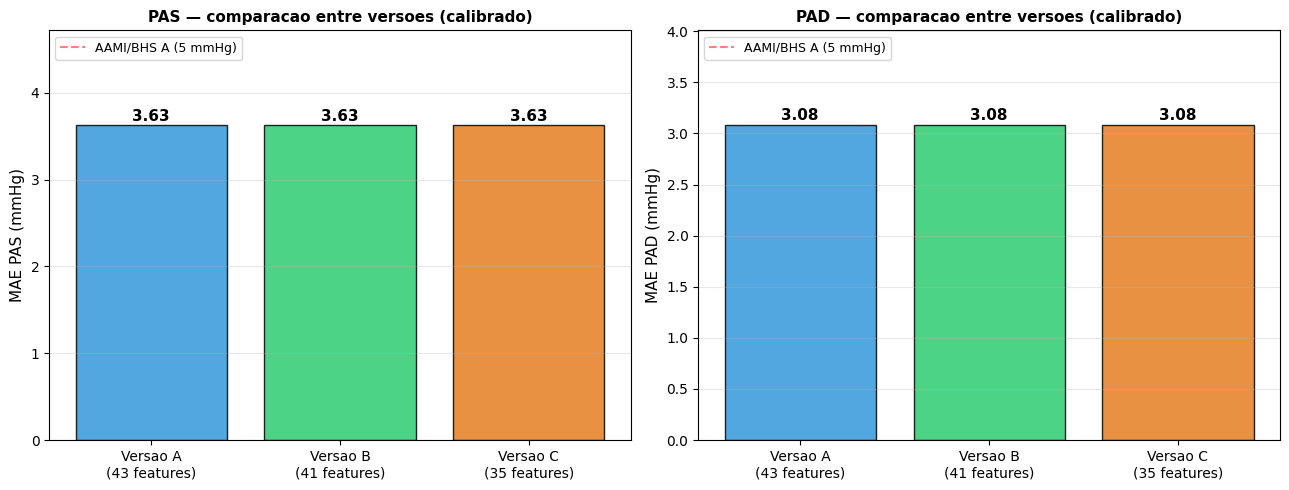

In [14]:
# Figura comparativa
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

posicoes = np.arange(3)
versoes = ["A", "B", "C"]
labels = [f"Versao {v}\n({len(CONFIGURACOES[v]['features'])} features)"
          for v in versoes]

mae_sys = [resultados[v]["m_sys_cal"]["MAE"] for v in versoes]
mae_dia = [resultados[v]["m_dia_cal"]["MAE"] for v in versoes]

cores = ["#3498db", "#2ecc71", "#e67e22"]

# PAS
ax = axes[0]
barras = ax.bar(posicoes, mae_sys, color=cores, edgecolor="black", alpha=0.85)
for barra, val in zip(barras, mae_sys):
    ax.text(barra.get_x() + barra.get_width()/2, barra.get_height() + 0.05,
            f"{val:.2f}", ha="center", fontsize=11, fontweight="bold")
ax.axhline(y=5, color="red", linestyle="--", alpha=0.5, label="AAMI/BHS A (5 mmHg)")
ax.set_xticks(posicoes)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("MAE PAS (mmHg)", fontsize=11)
ax.set_title("PAS — comparacao entre versoes (calibrado)",
             fontsize=11, fontweight="bold")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3, axis="y")
ax.set_ylim([0, max(mae_sys) * 1.3])

# PAD
ax = axes[1]
barras = ax.bar(posicoes, mae_dia, color=cores, edgecolor="black", alpha=0.85)
for barra, val in zip(barras, mae_dia):
    ax.text(barra.get_x() + barra.get_width()/2, barra.get_height() + 0.05,
            f"{val:.2f}", ha="center", fontsize=11, fontweight="bold")
ax.axhline(y=5, color="red", linestyle="--", alpha=0.5, label="AAMI/BHS A (5 mmHg)")
ax.set_xticks(posicoes)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("MAE PAD (mmHg)", fontsize=11)
ax.set_title("PAD — comparacao entre versoes (calibrado)",
             fontsize=11, fontweight="bold")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3, axis="y")
ax.set_ylim([0, max(mae_dia) * 1.3])

plt.tight_layout()
caminho_fig = PASTA_FIGS / "comparacao_versoes_ABC.png"
plt.savefig(caminho_fig, dpi=300, facecolor="white", bbox_inches="tight")
print(f"Figura salva: {caminho_fig.name}")
plt.show()

## 7. Salvamento dos modelos retreinados

Para cada uma das três versões, treina-se um Random Forest no **dataset completo** (sem holdout, igual ao NB03), que servirá como modelo de produção. Esses modelos serão aplicados ao PulseDB nos próximos notebooks.

⚠️ **Nota metodológica**: os modelos out-of-fold (gerados dentro do LOSO da Seção 5) são utilizados apenas para avaliação. Os modelos salvos a seguir são treinados em todos os 22 sujeitos para máxima generalização.


In [15]:
# Treina e salva os modelos finais (em dataset completo)
modelos_salvos = []

for vid in ["A", "B", "C"]:
    cfg = CONFIGURACOES[vid]
    X_completo = df_model[cfg["features"]].values.astype(np.float32)

    print(f"\nVersao {vid} ({len(cfg['features'])} features):")

    # PAS
    rf_sys = RandomForestRegressor(**RF_PARAMS)
    rf_sys.fit(X_completo, y_sys)
    nome_sys = f"rf_sys_v{vid}.joblib"
    joblib.dump(rf_sys, PASTA_MODELO / nome_sys)
    tam_mb = (PASTA_MODELO / nome_sys).stat().st_size / (1024**2)
    print(f"  Salvo: {nome_sys}  ({tam_mb:.1f} MB)")
    modelos_salvos.append(nome_sys)

    # PAD
    rf_dia = RandomForestRegressor(**RF_PARAMS)
    rf_dia.fit(X_completo, y_dia)
    nome_dia = f"rf_dia_v{vid}.joblib"
    joblib.dump(rf_dia, PASTA_MODELO / nome_dia)
    tam_mb = (PASTA_MODELO / nome_dia).stat().st_size / (1024**2)
    print(f"  Salvo: {nome_dia}  ({tam_mb:.1f} MB)")
    modelos_salvos.append(nome_dia)

print(f"\nTotal de modelos salvos: {len(modelos_salvos)}")


Versao A (43 features):
  Salvo: rf_sys_vA.joblib  (106.8 MB)
  Salvo: rf_dia_vA.joblib  (106.8 MB)

Versao B (41 features):
  Salvo: rf_sys_vB.joblib  (110.1 MB)
  Salvo: rf_dia_vB.joblib  (109.8 MB)

Versao C (35 features):
  Salvo: rf_sys_vC.joblib  (112.4 MB)
  Salvo: rf_dia_vC.joblib  (112.2 MB)

Total de modelos salvos: 6


In [16]:
# Salva tambem a lista de features de cada versao (para uso nos proximos notebooks)
import json

config_export = {}
for vid, cfg in CONFIGURACOES.items():
    config_export[vid] = {
        "nome": cfg["nome"],
        "features": cfg["features"],
        "n_features": len(cfg["features"]),
    }

caminho_json = PASTA_DADOS / "_configuracoes_modelos.json"
with open(caminho_json, "w", encoding="utf-8") as f:
    json.dump(config_export, f, indent=2, ensure_ascii=False)

print(f"Configuracoes salvas em: {caminho_json.name}")

# Salva tabela comparativa em CSV
caminho_tabela = PASTA_DADOS / "_comparacao_versoes_nb06.csv"
df_resultados.to_csv(caminho_tabela, index=False)
print(f"Tabela comparativa salva em: {caminho_tabela.name}")

Configuracoes salvas em: _configuracoes_modelos.json
Tabela comparativa salva em: _comparacao_versoes_nb06.csv


## 8. Conclusões e próximos passos

### 8.1 Validações realizadas

- ✅ Três versões do modelo treinadas: A (43 features), B (41), C (35)
- ✅ LOSO + calibração linear aplicados a todas as versões
- ✅ Métricas BHS e AAMI calculadas para cada versão
- ✅ Modelos finais salvos: `rf_sys_vA/B/C.joblib` e `rf_dia_vA/B/C.joblib`
- ✅ Configurações exportadas para `_configuracoes_modelos.json`

### 8.2 Decisão sobre a versão a usar no PulseDB

A decisão final sobre qual versão usar na validação externa será orientada pelos seguintes critérios:

1. **Aplicabilidade técnica**: a Versão C é a única que pode ser aplicada diretamente ao PulseDB sem premissas adicionais sobre escala do sinal ou disponibilidade de ECG.

2. **Perda de desempenho aceitável**: caso a Versão C mantenha MAE pós-calibração < 5 mmHg para ambas as pressões, ela é considerada adequada conforme AAMI/ISO 81060-2.

3. **Defensabilidade científica**: a Versão C usa apenas features invariantes à escala — desfaz qualquer confusão entre "diferença de modelo" e "diferença de pré-processamento" na avaliação externa.

### 8.3 Achados relevantes para o relatório/artigo

Os resultados desta seção fornecem material para discussão crítica no artigo:

- Comparação direta entre versões mostra o **custo** de remover features
- A Versão B isola o efeito da remoção do PTT
- A Versão C isola o efeito conjunto de remover PTT + escala-dependentes
- Se as três versões tiverem desempenho semelhante (esperado), reforça-se a tese de que **a calibração linear por sujeito é o componente dominante**, não as features individuais

### 8.4 Próximo notebook

**NB07 — Extração de features no PulseDB AAMI Test**: aplicará a função `extract_pulse_features_v2` (adaptada para fs=125 Hz) aos 666 segmentos do PulseDB, gerando um CSV de features no mesmo formato do PTT-PPG, mas usando apenas as 35 features da Versão C.

---


In [17]:
print(f"Notebook 06 concluido em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")
print(f"Computador: {socket.gethostname()}")

Notebook 06 concluido em: 07/06/2026 13:13:17
Computador: NtebookLeticia
